# Optimizacija dimenzioniranja sončne elektrarne glede na tržne cene in profil odjema

## 1. Opis problema in cilj naloge
Cilj projektne naloge je določiti **optimalno nazivno moč sončne elektrarne (SE)** za konkreten odjem električne energije.

Pri analizi upoštevamo:
- urni profil porabe električne energije (telemetrija),
- urne borzne SPOT cene električne energije v Sloveniji za leto 2024,
- simulirano urno proizvodnjo sončne elektrarne (PVGIS),
- vse tarifne postavke (omrežnina VT/MT, prispevki OIE+SPTE, trošarina) ter investicijske stroške (CAPEX) glede na velikost naprave,
- omejitev odjema

Cilj je najti takšno velikost SE, ki minimizira celotne letne stroške oziroma minimizira **ekonomsko dobo vračanja (EDV)**.

## 2. Pridobivanje podatkov s spleta
Podatke zajemamo neposredno prek dveh javnih spletnih vmesnikov (API):
1. **Energy-Charts API**: Borzne SPOT cene električne energije za območje Slovenije (`SI`).
2. **PVGIS API (Evropska komisija)**: Simulacija urnega sončnega obsevanja in proizvodnje za 1 kW sončne elektrarne na lokaciji, kjer jo želimo postaviti.

In [18]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import model_funkcije

from zajem_podatkov import prenesi_spot_cene, prenesi_proizvodnjo
from model_funkcije import (
    celotna_bilanca,
    formatiraj_eur,
    izracunaj_f,
    ocisti_ceno,
)

In [19]:
#Vnos željene lokacije
vnos_lat = input(f"Vnesite zemljepisno širino, kjer bo postavljena SE (ali pritisnite Enter za Ljubljana): ").strip()
if vnos_lat == "":
     lat = 46.0569
else:
    try:
        lat = float(vnos_lat.replace(',','.'))
    except ValueError:
        print("Vaš vnos ni veljaven. Uporabljam privzeto vrednost (Ljubljana).")
vnos_lon = input(f"Vnesite zemljepisno dolžino, kjer bo postavljena SE (ali pritisnite Enter za Ljubljana): ").strip()
if vnos_lon == "":
     lon = 14.5058
else:
    try:
        lon = float(vnos_lon.replace(',','.'))
    except ValueError:
        print("Vaš vnos ni veljaven. Uporabljam privzeto vrednost (Ljubljana).")
print(f"Izbrana lokacija za SE: širina = {lat:.4f}, dolžina = {lon:.4f}")

if __name__ == "__main__": #da se ne izvaja če datoteko samo importam kam drugam
    print("=== ZAGON PRENOSA PODATKOV S SPLETA ===")
    prenesi_spot_cene(leto=2024, drzava="SI")
    prenesi_proizvodnjo(lat, lon, leto=2020)
    print("=== PRENOS USPEŠNO ZAKLJUČEN ===")

Izbrana lokacija za SE: širina = 46.0569, dolžina = 14.5058
=== ZAGON PRENOSA PODATKOV S SPLETA ===
Prenašam SPOT cene za državo SI za leto 2024...
 -> SPOT cene uspešno shranjene v: c:\Users\Nika\Documents\Projektna_naloga_UVP\projektna-naloga-programiranje\podatki\spot_cene.csv (št. vrstic: 8784)
[2/2] Prenašam podatke o sončnem obsevanju s PVGIS za lokacijo (46.0569, 14.5058)...
 -> PVGIS podatki uspešno shranjeni v: c:\Users\Nika\Documents\Projektna_naloga_UVP\projektna-naloga-programiranje\podatki\pvgis_proizvodnja.csv (št. vrstic: 8784)
=== PRENOS USPEŠNO ZAKLJUČEN ===


## 1. Funkcije za izračune in obdelavo podatkov
Spodaj so definirane funkcije za čiščenje cen, oblikovanje zneskov ter matematični modeli za izračun bilanc in stroškov.

## 2. Vnos parametrov in uvoz podatkov
Nalaganje podatkov o SPOT cenah, PVGIS sončni proizvodnji ter Excel datoteke s telemetrijo in tarifami.

In [20]:
# ==========================================
# 2. PODATKI 
# ==========================================
#Uporabnik ima možnost, da podatke vnese sam ali uporabi moj model.
#Vnos omejitve moči:
vnos_moc = input("Vnesite priključno moč / omejitev odjema v kW [privzeta vrednost: 300]: ").strip()
if vnos_moc == "":
    limit_moci_kw = 300.0
else:
    try:
        limit_moci_kw = float(vnos_moc.replace(',','.'))
    except ValueError:
        print("Vaš vnos ni veljaven. Uporabljam privzeto vrednost 300 kW.")
print(f"Izbrana omejitev moči: {limit_moci_kw:.1f} kW")
model_funkcije.limit_moci_kw = limit_moci_kw

#Vnos lastne telemetrije:
privzeta_datoteka = "Podatki_Optimizacija1.xlsx"
vnos_datoteka = input(f"Vnesite ime Excel datoteke z meritvami (ali pritisnite Enter za '{privzeta_datoteka}'): ").strip()

if vnos_datoteka == "":
    pot_excel = os.path.join(os.getcwd(), privzeta_datoteka)
else:
    pot_excel = os.path.join(os.getcwd(), vnos_datoteka)

if not os.path.exists(pot_excel):
        print(f"OPOZORILO: Datoteka '{pot_excel}' ne obstaja! Uporabljena bo privzeta datoteka '{privzeta_datoteka}'.")
        pot_excel = os.path.join(os.path.dirname(__file__), privzeta_datoteka)  
print(f"Berem podatke iz: {os.path.basename(pot_excel)}")
     
MAPA_PODATKI = os.path.join(os.getcwd(), "podatki")
df_spot = pd.read_csv(os.path.join(MAPA_PODATKI, "spot_cene.csv"))
df_pvgis = pd.read_csv(os.path.join(MAPA_PODATKI, "pvgis_proizvodnja.csv"))

#Podatki iz mojih excelov(15-min meritve odjema, capex in tarife):
vsi_listi = pd.read_excel(pot_excel, sheet_name=None) #sheet_name = None pomeni da prebere vse liste v excelu
df_odjem_15min = vsi_listi["Telemetrija"]
df_capex = vsi_listi["Cenik_SE"]
df_stroski = vsi_listi["Tarife"].copy().set_index('Postavka') #Stolpec 'Postavka' nastavi kot indeks tabele (vrstice so sedaj poimenovane po posameznih postavkah stroškov, npr. omrežnina, energija ipd., kar omogoča enostaven dostop do vrednosti prek df_stroski.loc['Ime_postavke'])
df_stroski['Cena_num'] = df_stroski['Cena'].apply(ocisti_ceno) #.apply pokliče funkcijo za vsako vrstico

#15-min podatke pretvorim v urne
df_odjem_15min['Timestamp'] = pd.to_datetime(df_odjem_15min['Timestamp'])
df_odjem_15min = df_odjem_15min.set_index('Timestamp') # vrstice seindeksirajo po času, timestamp ni več navaden stolpec
df_odjem = df_odjem_15min.resample('1h').agg({ #grupira podatke po urah
    'reg_A_plus': 'sum', #porabe seštejem
    'Tarifa (VT/NT)': 'first' #za tarifo uporabim tisto ki je bila prva
}).reset_index()


df_spot['Timestamp'] = pd.to_datetime(df_spot['Timestamp'])
df_pvgis['Timestamp'] = pd.to_datetime(df_pvgis['Timestamp'])
#varovalka, če bi izbrali kombinacijo let, ki nimajo isto dni
st_ur = min(len(df_spot), len(df_pvgis), len(df_odjem))

#združitev
df_leto = pd.DataFrame({
    'Timestamp': df_spot['Timestamp'].iloc[:st_ur].values,
    'SPOT_EUR_MWh': df_spot['SPOT_EUR_MWh'].iloc[:st_ur].values,
    'Proizvodnja_normirano': df_pvgis['Proizvodnja_normirano'].iloc[:st_ur].values / df_pvgis['Proizvodnja_normirano'].iloc[:st_ur].values.sum(),
    'Odjem_kWh': df_odjem['reg_A_plus'].iloc[:st_ur].values,
    'Tarifa (VT/NT)': df_odjem['Tarifa (VT/NT)'].iloc[:st_ur].values
})
#Vektorji za nadaljne računanje
poraba = df_leto['Odjem_kWh'].values
bazicna_proizvodnja = df_leto['Proizvodnja_normirano'].values
SPOT_cena = df_leto['SPOT_EUR_MWh'].values
tarifa = df_leto['Tarifa (VT/NT)'].values

Izbrana omejitev moči: 300.0 kW
Berem podatke iz: Podatki_Optimizacija1.xlsx


## 3. Optimizacija samooskrbe na letni in dnevni ravni
Iskanje optimalne velikosti glede na največjo samooskrbnost skozi celotno leto ter za povprečen dan.

OPTIMIZACIJA SONČNA ELEKTRARNA
------------------------------------------------------------
CILJ: največja samooskrbnost
Optimalna letna količna proizvedene energije: 548548.59 kWh
Optimalna velikost: 522.43 kW


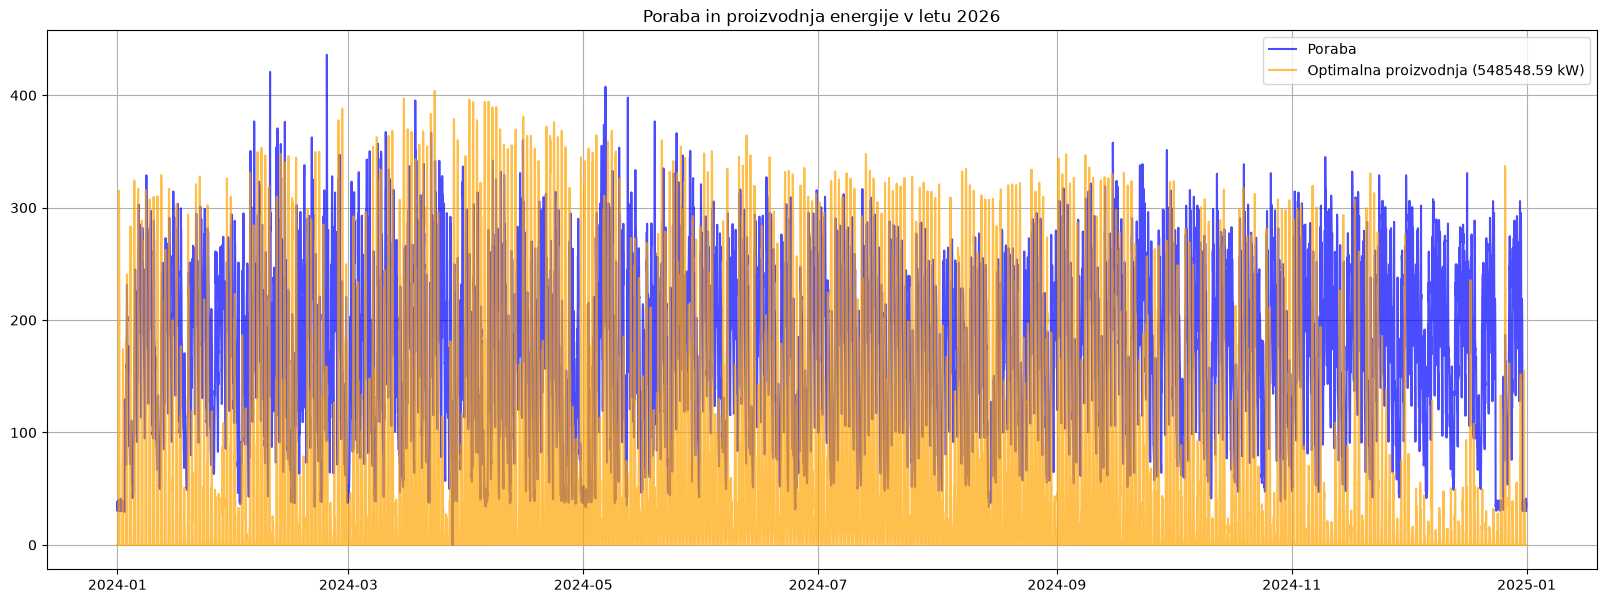

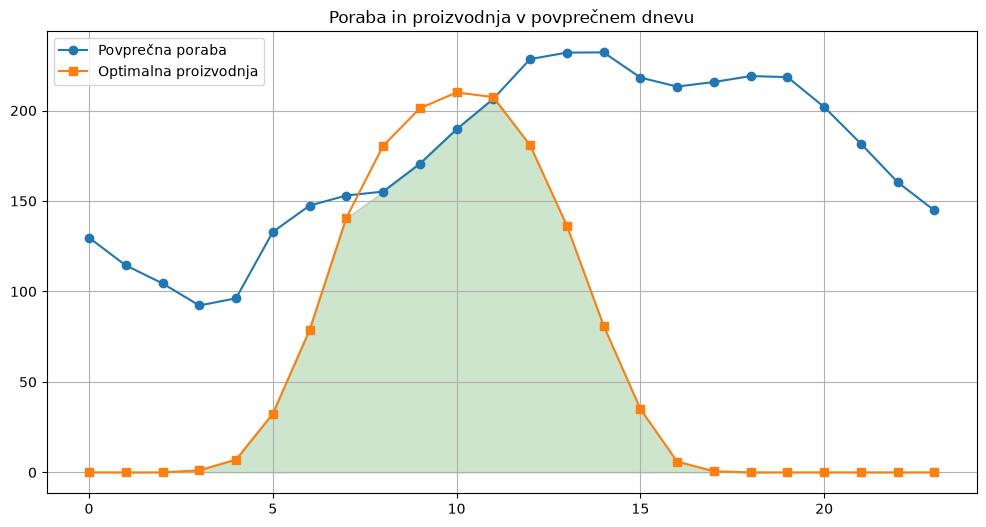

In [21]:
# ==========================================
# 3. IZVEDBA (Izračuni in grafi)
# ==========================================

print("OPTIMIZACIJA SONČNA ELEKTRARNA")
print("-" * 60)

# 1. Letna raven
print("CILJ: največja samooskrbnost")
velikosti = np.linspace(0.1, 1000000, 1000) #tu so velikosti glede na letno proizvedeno energijo
rezultati = [izracunaj_f(i, poraba, bazicna_proizvodnja) for i in velikosti]
optimalni_i = velikosti[np.argmax(rezultati)] #argmax izlušči indeks od najboljšega rezultata
proizvodnja_optimalna = bazicna_proizvodnja * optimalni_i
print(f"Optimalna letna količna proizvedene energije: {optimalni_i:.2f} kWh")
print(f"Optimalna velikost: {optimalni_i / 1050:.2f} kW")

# Graf 1
plt.figure(figsize=(20, 7))
plt.plot(df_leto['Timestamp'], df_leto['Odjem_kWh'], label='Poraba', color='blue', alpha=0.7)
plt.plot(df_leto['Timestamp'], proizvodnja_optimalna, label=f'Optimalna proizvodnja ({optimalni_i:.2f} kW)', color='orange', alpha=0.7)
plt.title('Poraba in proizvodnja energije v letu 2026')
plt.legend()
plt.grid(True)#pomožna mreža v ozadju
plt.show()

# 2. Povprečne ure
df_ura = df_leto.groupby(df_leto['Timestamp'].dt.hour).mean(numeric_only=True) #razvrsti skupaj podatke z istimi urami in (samo za številske) izračuna povprečje
povprecna_poraba = df_ura['Odjem_kWh'].values
povprečna_proizvodnja = df_ura['Proizvodnja_normirano'].values

# Graf 2
plt.figure(figsize=(12, 6))
ure = range(24)
proizvodnja_optimalna_ura = povprečna_proizvodnja * optimalni_i
plt.plot(ure, povprecna_poraba, label='Povprečna poraba', marker='o')
plt.plot(ure, proizvodnja_optimalna_ura, label='Optimalna proizvodnja', marker='s')
plt.fill_between(ure, np.minimum(povprecna_poraba, proizvodnja_optimalna_ura), color='green', alpha=0.2)
plt.title('Poraba in proizvodnja v povprečnem dnevu')
plt.legend()
plt.grid(True)
plt.show()

## 4. Ekonomska optimizacija (SPOT cene, CAPEX in celotna bilanca)
Izračun stroškovnih bilanc glede na tržne SPOT cene, investicijske stroške (CAPEX) in dajatve ter iskanje optimalne velikosti glede na ekonomsko dobo vračanja (EDV).


------------------------------------------------------------
CILJ: NAJNIŽJI CELOTNI LETNI STROŠEK - brez upoštevanja capex
Optimalna velikost: 900 kW
Letni strošek s SE: 171115.40 €
Letni strošek brez SE: 245041.08 €
Prihranek s SE: 73925.68 €
------------------------------------------------------------
 REZULTATI ZA VSE VELIKOSTI SE 
Velikost SE:   100.0 kW | EDV: 5.816 let | Letni prihranek: 11010.20 € | Donosnost:  5.16 %
Velikost SE:   150.0 kW | EDV: 5.445 let | Letni prihranek: 16603.17 € | Donosnost:  5.51 %
Velikost SE:   200.0 kW | EDV: 5.183 let | Letni prihranek: 22163.85 € | Donosnost:  5.79 %
Velikost SE:   250.0 kW | EDV: 5.132 let | Letni prihranek: 27521.14 € | Donosnost:  5.85 %
Velikost SE:   300.0 kW | EDV: 5.148 let | Letni prihranek: 32649.03 € | Donosnost:  5.83 %
Velikost SE:   350.0 kW | EDV: 5.189 let | Letni prihranek: 37471.31 € | Donosnost:  5.78 %
Velikost SE:   400.0 kW | EDV: 5.258 let | Letni prihranek: 41909.84 € | Donosnost:  5.71 %
Velikost SE:   500.

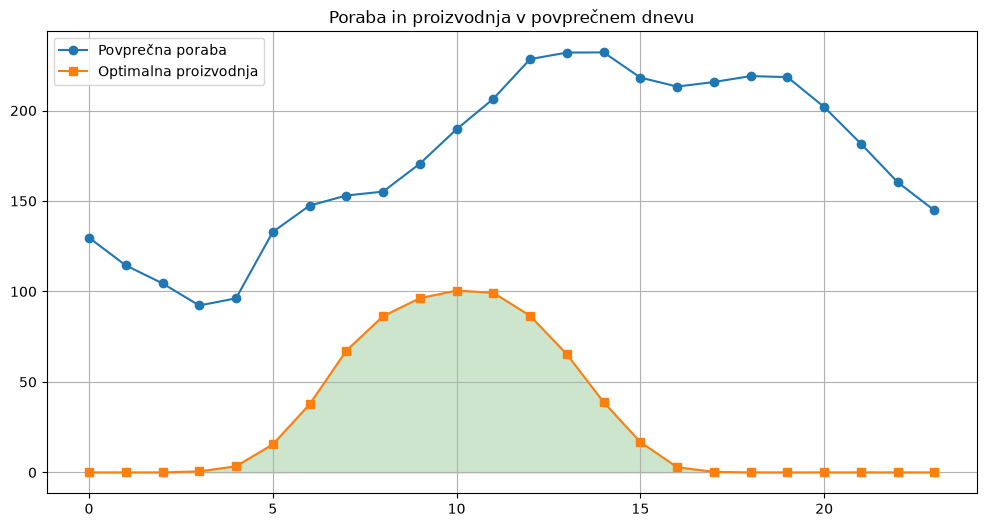

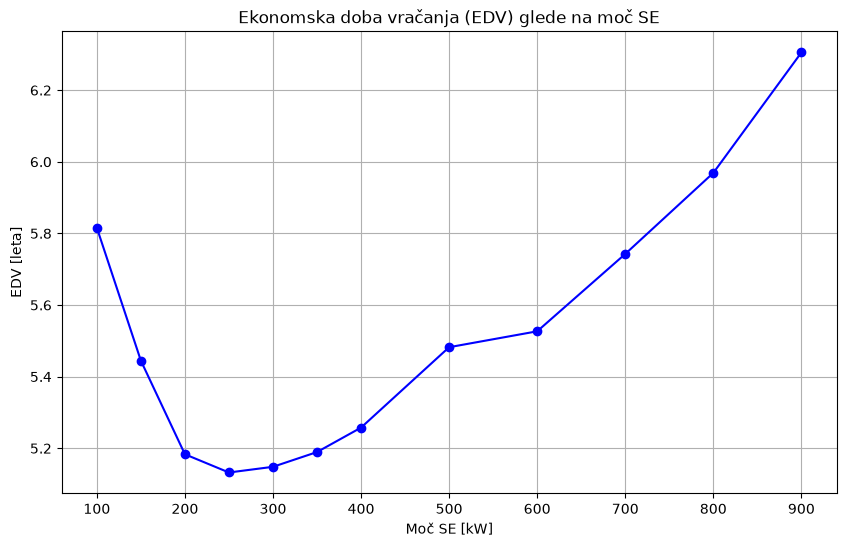


[USPEH] Rezultati so shranjeni v datoteko: Rezultati_Optimizacije_250kW.xlsx


In [22]:
scenariji = df_capex.copy()
# 5. Celotna bilanca
print("-" * 60)
print("CILJ: NAJNIŽJI CELOTNI LETNI STROŠEK - brez upoštevanja capex")
scenariji['Rezultat_dict'] = scenariji.apply(lambda row: celotna_bilanca(row, poraba, bazicna_proizvodnja, df_stroski, SPOT_cena, df_leto), axis=1) # doda v tabelo slovarje v vsako vrstico
scenariji['Strosek_EUR'] = scenariji['Rezultat_dict'].apply(lambda x: x['Skupaj'])
#lamda je mini funkcija, ki jo uvedem da sprejme cel slovar in potem iz nje izluščim postavko 'Skupaj'

# Izračun stanja BREZ SE (po posameznih postavkah in skupaj)
omr_kwh_brez = np.where(df_leto['Tarifa (VT/NT)'] == "NT", 0.01695, 0.03724)
strosek_brez_spot = np.sum(poraba * (SPOT_cena/1000 + 5/1000)) * 1.13
strosek_brez_omr = (np.sum(poraba * omr_kwh_brez) + df_stroski.loc['PowerNetworkFee','Cena_num']* limit_moci_kw) * 1.13
strosek_brez_pris = (df_stroski.loc['DutyMeteringPoint','Cena_num']*12 + np.sum((df_stroski.loc['DutyOIEK','Cena_num']+df_stroski.loc['DutyPiOI','Cena_num'])*poraba)) * 1.13
strosek_brez_tros = np.sum(df_stroski.loc['ExciseTax','Cena_num'] * poraba) * 1.13
strosek_brez_SE_full = strosek_brez_spot + strosek_brez_omr + strosek_brez_pris + strosek_brez_tros

najboljsa_opcija_final = scenariji.loc[scenariji['Strosek_EUR'].idxmin()]
print(f"Optimalna velikost: {najboljsa_opcija_final['Moc_SE_kW']} kW")
print(f"Letni strošek s SE: {najboljsa_opcija_final['Strosek_EUR']:.2f} €")
print(f"Letni strošek brez SE: {strosek_brez_SE_full:.2f} €")
print(f"Prihranek s SE: {strosek_brez_SE_full - najboljsa_opcija_final['Strosek_EUR']:.2f} €")

# Rezultati za vse velikosti
print("-" * 60)
print(" REZULTATI ZA VSE VELIKOSTI SE ")
edv_seznam = []
for idx, row in scenariji.iterrows(): #idx je indeks, row so vsi podatki v vrstici, .iterrows() je ukaz in pandas, ki omogoča zanko for 
    prihranek_v = strosek_brez_SE_full - row['Strosek_EUR']
    edv_v = row['CAPEX_EUR'] / prihranek_v if prihranek_v > 0 else 0
    edv_seznam.append(edv_v)
    donosnost_v = (prihranek_v * 30) / row['CAPEX_EUR']
    print(f"Velikost SE: {row['Moc_SE_kW']:7.1f} kW | EDV: {edv_v:5.3f} let | Letni prihranek: {prihranek_v:5.2f} € | Donosnost: {donosnost_v:5.2f} %")


scenariji['EDV_let'] = edv_seznam
najboljsa_edv = scenariji.loc[scenariji['EDV_let'][scenariji['EDV_let']>0].idxmin()] #[scenariji['EDV_let']>0] vzame samo smiselne- vrne true/false
opt_res_edv = najboljsa_edv['Rezultat_dict']

# Tabela primerjave
print("-" * 60)
print("OPTIMALNA VELIKOST GLEDE NA EDV:")
print(f"Optimalna velikost: {najboljsa_edv['Moc_SE_kW']} kW")
print(f"Letni strošek s SE: {najboljsa_edv['Strosek_EUR']:.2f} €")
print(f"Letni strošek brez SE: {strosek_brez_SE_full:.2f} €")
prihranek_edv = strosek_brez_SE_full - najboljsa_edv['Strosek_EUR']
print(f"Prihranek s SE: {prihranek_edv:.2f} €")
print(f"EDV: {najboljsa_edv['EDV_let']:.2f} let")
opt_res_edv = najboljsa_edv['Rezultat_dict']
primerjava = {
    'Kategorija': ['Znesek energije', 'Znesek omrežnine', 'Znesek ostalih prispevkov', 'Znesek trošarine', 'Zaslužek od viškov', 'Znesek capex', 'SKUPAJ'],
    'Strošek pred': [round(strosek_brez_spot, 2), round(strosek_brez_omr, 2), round(strosek_brez_pris, 2), round(strosek_brez_tros, 2), 0, 0, round(strosek_brez_SE_full, 2)],
    'Strošek po': [opt_res_edv['Energija'], opt_res_edv['Omreznina'], opt_res_edv['Prispevki'], opt_res_edv['Trosarina'], -opt_res_edv['Viski'], opt_res_edv['CAPEX'], opt_res_edv['Skupaj']]
}
print("\nOcena letnega prihranka s sončno elektrarno:")
print(pd.DataFrame(primerjava))

#Graf-dnevna samooskrba z optimalno SE glede na najnižji EDV
plt.figure(figsize=(12, 6))
ure = range(24)
proizvodnja_optimalna_ura = povprečna_proizvodnja * najboljsa_edv['Moc_SE_kW'] * 1050
plt.plot(ure, povprecna_poraba, label='Povprečna poraba', marker='o')
plt.plot(ure, proizvodnja_optimalna_ura, label='Optimalna proizvodnja', marker='s')
plt.fill_between(ure, np.minimum(povprecna_poraba, proizvodnja_optimalna_ura), color='green', alpha=0.2)
plt.title('Poraba in proizvodnja v povprečnem dnevu')
plt.legend()
plt.grid(True)
plt.show()

# Končni graf
plt.figure(figsize=(10,6))
plt.plot(scenariji['Moc_SE_kW'], scenariji['EDV_let'], marker='o', color='blue')
plt.title('Ekonomska doba vračanja (EDV) glede na moč SE')
plt.xlabel('Moč SE [kW]')
plt.ylabel('EDV [leta]')
plt.grid(True)
plt.show()

#excel tabela:
# 1. Priprava podatkov za tabelo (izračunamo še stolpec Prihranek)
df_koncna_tabela = pd.DataFrame(primerjava)

# Izračunamo prihranek
df_koncna_tabela['Prihranek'] = df_koncna_tabela['Strošek pred'] - df_koncna_tabela['Strošek po']


# Ustvarimo kopijo za izvoz, da ne pokvarimo originalnih številk za izračune
df_za_export = df_koncna_tabela.copy()
for col in ['Strošek pred', 'Strošek po', 'Prihranek']:
    df_za_export[col] = df_za_export[col].apply(formatiraj_eur)

# 3. Izvoz v Excel
ime_datoteke = f"Rezultati_Optimizacije_{najboljsa_edv['Moc_SE_kW']}kW.xlsx"
df_za_export.to_excel(ime_datoteke, index=False)

print(f"\n[USPEH] Rezultati so shranjeni v datoteko: {ime_datoteke}")

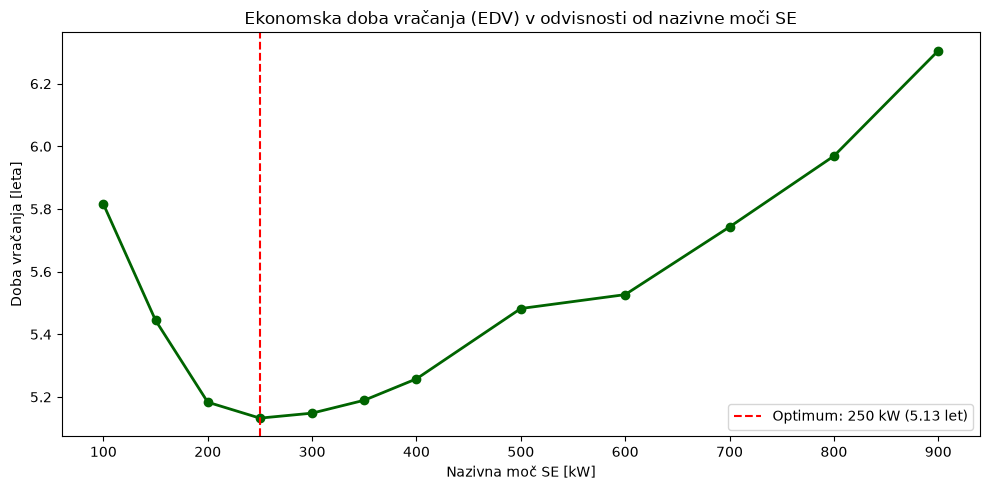

In [23]:
# Graf odvisnosti EDV od moči SE
plt.figure(figsize=(10, 5))
plt.plot(scenariji['Moc_SE_kW'], scenariji['EDV_let'], marker='o', color='darkgreen', linewidth=2)
plt.axvline(najboljsa_edv['Moc_SE_kW'], color='red', linestyle='--', label=f"Optimum: {najboljsa_edv['Moc_SE_kW']} kW ({najboljsa_edv['EDV_let']:.2f} let)")
plt.title('Ekonomska doba vračanja (EDV) v odvisnosti od nazivne moči SE')
plt.xlabel('Nazivna moč SE [kW]')
plt.ylabel('Doba vračanja [leta]')
plt.legend()
plt.tight_layout()
plt.show()

## 8. Zaključek
Analiza nam je glede na naše vhodne podatke izbrala najbolj ekonomično velikost sončne elektrarne za naše potrebe. 